# Portfolio Project: Online Retail Exploratory Data Analysis with Python

## Dataset

The dataset you will be working with is the "Online Retail" dataset. It contains transactional data of an online retail store from 2010 to 2011. The dataset is available as a .xlsx file named `Online Retail.xlsx`. This data file is already included in the Coursera Jupyter Notebook environment, however if you are working off-platform it can also be downloaded [here](https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx).

The dataset contains the following columns:

- InvoiceNo: Invoice number of the transaction
- StockCode: Unique code of the product
- Description: Description of the product
- Quantity: Quantity of the product in the transaction
- InvoiceDate: Date and time of the transaction
- UnitPrice: Unit price of the product
- CustomerID: Unique identifier of the customer
- Country: Country where the transaction occurred

## Introduction 



This project aims to analyse an online retail company's sales performance using transactional data from 2010 to 2011. Through exploratory data analysis (EDA) using Python, we will investigate sales trends, identify the highest revenue-generating products, examine customer purchasing behaviour, and evaluate geographic sales performance. The objective is to uncover meaningful insights that explain the company's historical sales performance and provide data-driven recommendations for improving business performance.

## Importing libraries 

Before beginning our analysis, we will import the necessary Python libraries to help us process, analyse, and visualise the data. We will use Pandas for data manipulation and analysis, NumPy for numerical calculations, and Matplotlib and Seaborn for creating visualisations. These libraries will provide the tools needed to explore the dataset, identify sales patterns, and generate meaningful business insights.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


## Loading the data into data frame and displaying the first few rows.

The reason why we are displaying the first few rows of the data is so that we can see what we are working with and what our data set looks like. This will allow us to spot errors within the data which could impact our analysis. 


In [2]:

# Load the Online Retail dataset
df = pd.read_excel("Online Retail.xlsx")

# Display the first five rows
df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Data qaulity assessment 

This part is a crucial step before we actually perform our analysis, we might have missing values, incorrect format and duplicate records that could skew our analysis. This process will help us identify issues that could distort revenue calculations and lead to misleading business conclusions 

In [3]:

# 1. Check the number of rows and columns in the dataset
print("Dataset Shape:", df.shape)

# 2. Check the column names, data types, and non-null values
print("\nDataset Information:")
df.info()

# 3. Check for missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

# 4. Check for duplicate records in the dataset
print("\nDuplicate Records:", df.duplicated().sum())

# 5. Generate descriptive statistics for numerical columns
print("\nDescriptive Statistics:")
display(df.describe())

# 6. Check for transactions with zero or negative quantities
print("\nTransactions with zero or negative quantities:",
      (df["Quantity"] <= 0).sum())

# 7. Check for transactions with zero or negative unit prices
print("\nTransactions with zero or negative prices:",
      (df["UnitPrice"] <= 0).sum())

# 8. Check for cancelled invoices identified by the letter C
print("\nCancelled Invoice Rows:",
      df["InvoiceNo"].astype(str).str.startswith("C").sum())


Dataset Shape: (541909, 8)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records: 5268

Descriptive Statistics:


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000



Transactions with zero or negative quantities: 10624

Transactions with zero or negative prices: 2517

Cancelled Invoice Rows: 9288




### Investigating Data Quality Issues

Before cleaning the dataset, we conducted a more detailed investigation into duplicate records, negative quantities, zero or negative prices, and unusually large transactions. The purpose was to understand whether these records represented data errors or legitimate business activities, such as product returns and cancelled orders. This investigation allows us to make informed cleaning decisions, preserve valuable information, and ensure that our sales analysis produces accurate and reliable results.

In [4]:

# Display the first 10 records with negative quantities
display(df[df["Quantity"] < 0].head(10))

# Display the first 10 records with zero or negative prices
display(df[df["UnitPrice"] <= 0].head(10))

# Examine transactions with unusually large quantities
display(df[df["Quantity"].abs() > 10000])

# Check how many records have missing Customer IDs
print("Missing Customer IDs:", df["CustomerID"].isnull().sum())

# Check the number of duplicate records
print("Duplicate Records:", df.duplicated().sum())


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256.0,United Kingdom
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom


Missing Customer IDs: 135080
Duplicate Records: 5268


### Data Cleaning 
Before conducting our exploratory data analysis, we will clean and prepare the dataset to improve the accuracy and reliability of our findings. This involves addressing duplicate records, missing information, invalid prices, and cancelled transactions. We will preserve returns for net revenue analysis while separating completed sales from cancellations, allowing us to evaluate the company's sales performance more accurately.

In [5]:


# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Remove records with missing product descriptions
df_clean = df_clean.dropna(subset=["Description"])

# Remove records with zero or negative unit prices
df_clean = df_clean[df_clean["UnitPrice"] > 0]

# Calculate revenue for each transaction
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# Check the number of remaining records
print("Original Records:", len(df))
print("Cleaned Records:", len(df_clean))

# Display the first five rows of the cleaned dataset
display(df_clean.head())


Original Records: 541909
Cleaned Records: 534129
Completed Sales Rows: 524878
Return Rows: 9251
Rows Requiring Review: 0

Remaining Missing Values:
InvoiceNo               0
StockCode               0
Description             0
Quantity                0
InvoiceDate             0
UnitPrice               0
CustomerID         132565
Country                 0
IsCancelled             0
TransactionType         0
Revenue                 0
Year                    0
Month                   0
YearMonth               0
dtype: int64

Remaining Duplicate Records: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,TransactionType,Revenue,Year,Month,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,Sale,15.30,2010,12,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,Sale,20.34,2010,12,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,Sale,22.00,2010,12,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,Sale,20.34,2010,12,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,Sale,20.34,2010,12,2010-12


### Total Revenue Analysis 

The objective of this analysis is to determine how much revenue the company generated during the period under investigation. By calculating revenue from the quantity of products sold and their unit prices, we can establish a baseline for evaluating the company's overall sales performance. We will also account for product returns to better understand net revenue.

In [6]:

# Calculate revenue for each transaction line
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# Calculate the company's total net revenue
total_revenue = df_clean["Revenue"].sum()

# Display the total net revenue
print(f"Total Net Revenue: £{total_revenue:,.2f}")


Total Net Revenue: £9,748,131.07


### Monthly Revenue Analysis

The objective of this analysis is to examine how the company's revenue changed from month to month during the period under investigation. By calculating and visualising monthly net revenue, we can identify periods of growth or decline, fluctuations in sales performance, and months that may require further investigation.

Monthly Net Revenue:


YearMonth
2010-12     746723.610
2011-01     558448.560
2011-02     497026.410
2011-03     682013.980
2011-04     492367.841
2011-05     722094.100
2011-06     689977.230
2011-07     680156.991
2011-08     703510.580
2011-09    1017596.682
2011-10    1069368.230
2011-11    1456145.800
2011-12     432701.060
Freq: M, Name: Revenue, dtype: float64

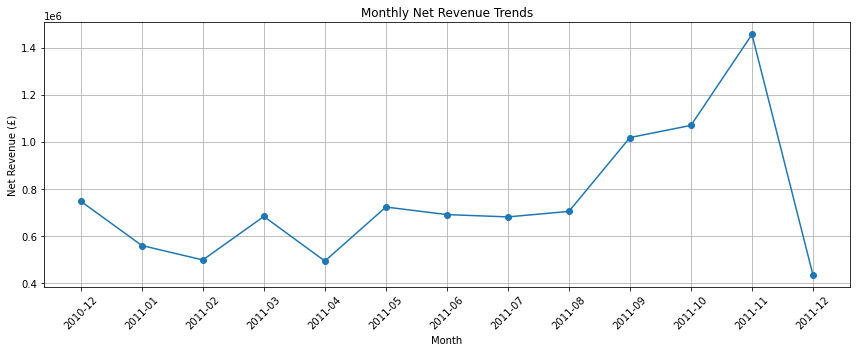

In [7]:

# Create a YearMonth variable to group transactions by month
df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.to_period("M")

# Calculate total net revenue for each month
monthly_revenue = df_clean.groupby("YearMonth")["Revenue"].sum()

# Display monthly revenue
print("Monthly Net Revenue:")
display(monthly_revenue)

# Create a line chart showing monthly revenue trends
plt.figure(figsize=(12, 5))
plt.plot(monthly_revenue.index.astype(str),
         monthly_revenue.values, marker="o")

# Add a title and labels to the chart
plt.title("Monthly Net Revenue Trends")
plt.xlabel("Month")
plt.ylabel("Net Revenue (£)")

# Improve the readability of the chart
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

# Display the chart
plt.show()


### Monthly Revenue Findings

Monthly revenue fluctuated throughout the year, with a noticeable increase towards the end of 2011. November recorded the highest revenue, followed by a sharp decline in December. However, the December decline is misleading because the dataset only contains transactions from the beginning of the month. Overall, the company experienced stronger sales performance towards the end of the year.

### Product Revenue Analysis

The objective of this analysis is to identify which products contribute the most to the company's revenue. By comparing revenue generated across different products, we can determine the strongest revenue contributors and better understand which products play an important role in the company's overall sales performance.

Description
REGENCY CAKESTAND 3 TIER              164459.49
WHITE HANGING HEART T-LIGHT HOLDER     99612.42
PARTY BUNTING                          98243.88
JUMBO BAG RED RETROSPOT                92175.79
RABBIT NIGHT LIGHT                     66661.63
PAPER CHAIN KIT 50'S CHRISTMAS         63715.24
ASSORTED COLOUR BIRD ORNAMENT          58792.42
CHILLI LIGHTS                          53746.66
SPOTTY BUNTING                         42030.67
JUMBO BAG PINK POLKADOT                41584.43
Name: Revenue, dtype: float64

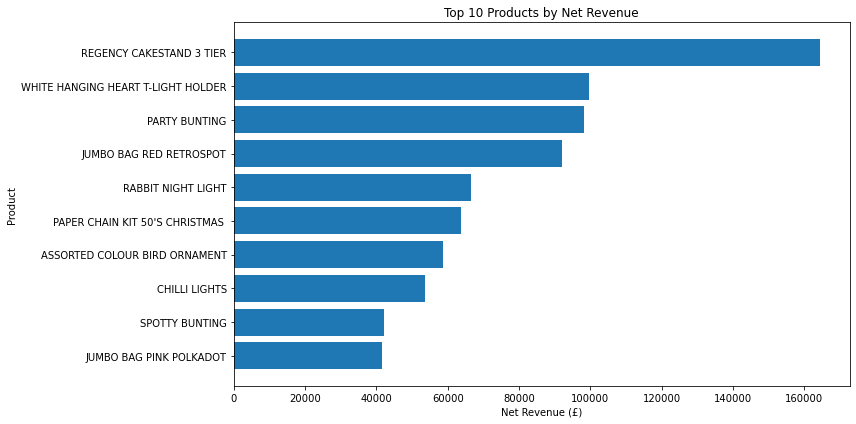

In [9]:


# Identify non-product entries to exclude from product analysis
non_products = ["DOTCOM POSTAGE", "POSTAGE", "Manual"]

# Filter out non-product entries while keeping the original cleaned dataset unchanged
product_data = df_clean[
    ~df_clean["Description"].isin(non_products)
]

# Calculate net revenue for each product, including returns
product_revenue = product_data.groupby("Description")["Revenue"].sum()

# Identify the top 10 products by net revenue
top_products = product_revenue.sort_values(ascending=False).head(10)

# Display the top 10 revenue-generating products
display(top_products)

# Create a horizontal bar chart showing the top 10 products
plt.figure(figsize=(12, 6))
plt.barh(top_products.index[::-1], top_products.values[::-1])

# Add the chart title and labels
plt.title("Top 10 Products by Net Revenue")
plt.xlabel("Net Revenue (£)")
plt.ylabel("Product")

# Improve the chart layout
plt.tight_layout()

# Display the chart
plt.show()



### Product Revenue Findings

The analysis revealed that Regency Cakestand 3 Tier was the company's highest revenue-generating product, significantly outperforming the other products in the top ten. Decorative homeware, party accessories, and gift-related items featured prominently among the strongest revenue contributors. These findings suggest that these product categories play an important role in the company's sales performance during the period analysed.

### Geographic Revenue Analysis

The objective of this analysis is to identify which national markets contribute the most to the company's revenue. By comparing net revenue across countries, we can determine where the company generates most of its sales, identify its strongest geographic markets, and assess its dependence on particular countries.

Country
United Kingdom    8.189252e+06
Netherlands       2.846615e+05
EIRE              2.629934e+05
Germany           2.215095e+05
France            1.973171e+05
Australia         1.370098e+05
Switzerland       5.636305e+04
Spain             5.475603e+04
Belgium           4.091096e+04
Sweden            3.658541e+04
Name: Revenue, dtype: float64

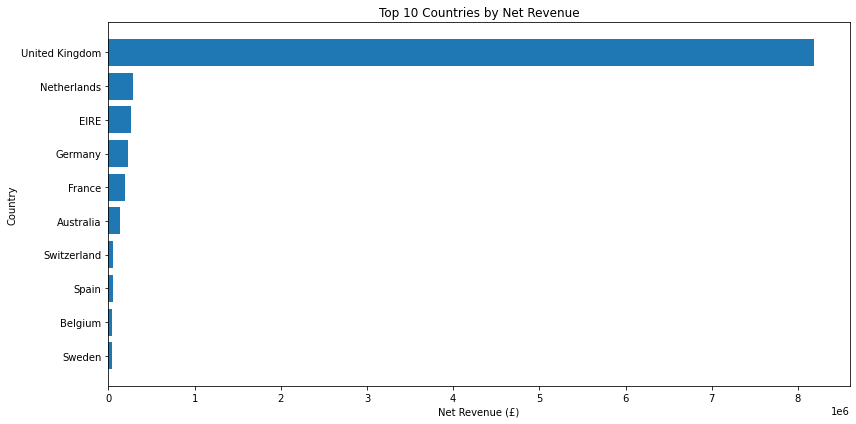

In [12]:


# Calculate total net revenue generated by each country
country_revenue = df_clean.groupby("Country")["Revenue"].sum()

# Identify the 10 countries generating the highest net revenue
top_countries = country_revenue.sort_values(ascending=False).head(10)

# Display the top 10 countries by net revenue
display(top_countries)

# Create a horizontal bar chart showing the top 10 countries
plt.figure(figsize=(12, 6))
plt.barh(top_countries.index[::-1], top_countries.values[::-1])

# Add a title and labels to the chart
plt.title("Top 10 Countries by Net Revenue")
plt.xlabel("Net Revenue (£)")
plt.ylabel("Country")

# Improve the chart layout
plt.tight_layout()

# Display the chart
plt.show()



### Geographic Revenue Findings

The analysis revealed that the United Kingdom is by far the company's largest revenue-generating market, contributing the overwhelming majority of total revenue. The Netherlands, Ireland, Germany and France were the strongest international markets, although their contributions were considerably smaller. These findings suggest that the company relies heavily on its domestic market, while also maintaining a presence in several international markets that could present opportunities for future growth.

## Findings and Conclusion

The analysis revealed that the company generated approximately £9.75 million in net revenue during the period investigated, with sales performance fluctuating throughout the year before increasing noticeably towards the end of 2011. November recorded the strongest monthly revenue.

In terms of product performance, **Regency Cakestand 3 Tier** was the highest revenue-generating product, while decorative homeware, party accessories, and gift-related products also performed well.

Geographically, the **United Kingdom dominated sales revenue**, with the Netherlands, Ireland, Germany, and France emerging as the strongest international markets. This suggests that the company is heavily dependent on its domestic market.

Overall, the analysis provided a clearer understanding of the company's historical sales performance and its main revenue contributors. However, the dataset lacked information on profitability, customer demographics, and marketing activities, limiting our ability to investigate the underlying drivers of performance or make more detailed business recommendations.

**In conclusion**, the company demonstrated stronger sales performance towards the end of the period, with revenue concentrated in its UK market and several leading products. Further analysis using more comprehensive business data would be necessary to identify the causes of these patterns and develop more targeted recommendations.